# NB1 · Evidence figures — *Grid event or data artefact?*

All figures that can be built from the raw data + rule engine v0 outputs, before any model:

| Fig | Content |
|---|---|
| 1 | City map (schematic) + coverage / state bars for all 17 zone series |
| 3 | 26–29 Jan 2023 (C05/C06): 15 zones stacked, hold & zero spans shaded |
| 4 | 31 Mar – 2 Apr 2024 (C12): held L1/L2 next to zeroed zones |
| 5 | Clock evidence: daily profiles before/after each clock date + corr(δ) curve (eq. 9) |
| E1 | C09 16 Jul 2023 candidate regional outage: city totals vs expected, overshoot |
| E2 | C11 Boujdour load transfer 16 Dec 2023 (conservation of current) |
| E3 | Single-zone events: start hour × weekday (G3 vs G4 maintenance window) |
| E4 | Signatures: exact-zero share η and restoration (r, π) by provisional type (H1, H2) |
| E5 | Single-zone outage gallery (C01, C02, C04, C07) |
| E6 | Catalogue overview timeline (all events by zone, coloured by type family) |
| E7 | Foum El Oued structural decline + midday/evening ratio |
| E8 | Marrakech timestamp audit (misordered midnight rows) |

**Inputs:** `data/raw/Data Morocco.xlsx`, `src/rules_v0.py`, `results/event_catalogue_v0/*.csv`.
**Outputs:** `results/figures/*.png|pdf`, `results/figures/clock_offsets.csv`, `results/figures/interp_runs.csv`.
Time axis = timestamps **as recorded** (no clock correction applied).

In [1]:
# ---- Setup: works locally (run from repo root or notebooks/) and on Colab ----
import sys, os, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Option A: repo cloned/copied to Drive -> MyDrive/grid-event-or-data-artefact
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

try:
    import openpyxl  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl"], check=True)

XLSX = ROOT / "data" / "raw" / "Data Morocco.xlsx"
CAT = ROOT / "results" / "event_catalogue_v0"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
assert XLSX.exists(), XLSX
print("ROOT =", ROOT)

ROOT = C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import rules_v0 as R          # reuse v0 loading / regularising / expected value => numbers match the catalogue

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False,
})

# One hue per class family (guide: artefacts one hue, grid events another, normal grey)
COL = dict(
    artefact="#C8553D",   # A-family
    grid="#2F6690",       # G-family
    normal="#9AA0A6",
    hold="#F2A541",       # held value span (A2/A3 evidence)
    interp="#2A9D8F",     # linearly interpolated span (constant first difference)
    zero="#C8553D",       # exact-zero span
    dead="#7B5EA7",       # dead but not exact zero (noise floor)
    missing="#222222",
    expected="#6C757D",
    trace="#1F2328",
)
TYPE_COL = {"A1_zero_fill_gap?": COL["artefact"], "G1_regional_outage?": "#0B2545", "G2_city_outage?": "#1D4E89",
            "G3_feeder_outage": "#3E7CB1", "G3m_partial_city": "#A3BFD9", "G4_planned_work?": "#6CC3E0"}
CITY_SHORT = {"Laayoune": "L", "Boujdour": "B", "Foum eloued": "F", "Marrakech": "M"}
SOUTH = R.SOUTH

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    print("saved", FIG / f"{name}.png")

def fmt_time(ax, fmt="%d %b\n%H:%M"):
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

## Load data (same preprocessing as rules_v0) and the v0 catalogue

In [3]:
raw = R.load(XLSX)                                            # dict city -> raw DataFrame
data = {c: R.regularise(c, df) for c, df in raw.items()}       # duplicates averaged, regular grid, NaN for missing
exp = {c: d.apply(lambda s, c=c: R.expected(s, c)) for c, d in data.items()}   # eq. 1

zero_ev = pd.read_csv(CAT / "zero_events.csv", parse_dates=["start", "end"])
stuck = pd.read_csv(CAT / "stuck_runs.csv", parse_dates=["start", "end"])
transf = pd.read_csv(CAT / "transfers.csv", parse_dates=["day"])
audit = pd.read_csv(CAT / "timestamp_audit.csv", parse_dates=["timestamp"])

for c, d in data.items():
    print(f"{c:12s} {d.shape[1]} zones  {d.index[0]} -> {d.index[-1]}  steps={len(d):,}  NaN steps={int(d.isna().any(axis=1).sum())}")
print(len(zero_ev), "dead events |", len(stuck), "stuck runs |", len(transf), "transfer candidates |", len(audit), "audit rows")

Laayoune     5 zones  2022-09-14 17:10:00 -> 2024-05-24 00:00:00  steps=88,890  NaN steps=12
Boujdour     3 zones  2022-09-14 17:10:00 -> 2024-05-24 00:00:00  steps=88,890  NaN steps=12
Foum eloued  7 zones  2022-09-14 17:10:00 -> 2024-05-24 00:00:00  steps=88,890  NaN steps=12
Marrakech    2 zones  2023-01-09 00:00:00 -> 2024-01-08 23:30:00  steps=17,520  NaN steps=25
72 dead events | 220 stuck runs | 13 transfer candidates | 421 audit rows


### State masks per step: exact zero, dead (eq. 4), held (eq. 6), missing

In [4]:
HOLD_PTS = 6        # >= 6 identical non-zero points
EPS = R.DEAD_REL    # 0.05

def hold_mask(x, min_pts=HOLD_PTS):
    same = (x.diff() == 0) & (x != 0) & x.notna()
    grp = (~same).cumsum()
    length = same.groupby(grp).transform("sum")          # number of 'same' steps in the run
    mark = same & (length >= min_pts - 1)
    first = mark.shift(-1, fill_value=False) & ~same      # the first point of each run
    return mark | first

def interp_mask(x, min_pts=HOLD_PTS):
    # runs of >= min_pts points on one straight line with non-zero slope (linear gap fill)
    dx = x.diff()
    lin = (dx.diff().abs() < 1e-8 * np.maximum(1, x.abs())) & (dx.abs() > 1e-12) & x.notna() & (x != 0)
    grp = (~lin).cumsum()
    length = lin.groupby(grp).transform("sum")           # k collinear 2nd differences => k+2 points
    mark = lin & (length >= min_pts - 2)
    return mark | mark.shift(-1, fill_value=False) | mark.shift(-2, fill_value=False)

states = {}   # city -> dict(state -> DataFrame[bool])
for c, d in data.items():
    e = exp[c]
    zero = d.eq(0)
    dead = (zero | (d <= EPS * e)) & d.notna()
    states[c] = dict(
        zero=zero,
        dead_nz=dead & ~zero,                              # dead but reading a noise floor
        hold=d.apply(hold_mask),
        interp=d.apply(interp_mask),
        missing=d.isna(),
    )
    print(c, {k: int(v.values.sum()) for k, v in states[c].items()})

Laayoune {'zero': 1465, 'dead_nz': 227, 'hold': 1728, 'interp': 1859, 'missing': 60}


Boujdour {'zero': 1413, 'dead_nz': 43, 'hold': 1623, 'interp': 745, 'missing': 36}


Foum eloued {'zero': 4323, 'dead_nz': 239, 'hold': 373, 'interp': 2550, 'missing': 84}


Marrakech {'zero': 101, 'dead_nz': 769, 'hold': 928, 'interp': 6, 'missing': 50}


## Generic stacked-zone plot (used for Fig. 3, Fig. 4, gallery)
One row per zone, raw value (black), expected value x̂ (grey dashed), spans shaded by state.

In [5]:
ZONE_ORDER = [(c, z) for c in SOUTH for z in data[c].columns]

def stack_plot(t0, t1, zones=ZONE_ORDER, title="", marks=(), row_h=0.55, highlight=(), show_expected=True):
    t0, t1 = pd.Timestamp(t0), pd.Timestamp(t1)
    fig, axes = plt.subplots(len(zones), 1, figsize=(10, row_h * len(zones) + 1.2), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (c, z) in zip(axes, zones):
        x = data[c][z][t0:t1]; xh = exp[c][z][t0:t1]; st = {k: v[z][t0:t1] for k, v in states[c].items()}
        tr = ax.get_xaxis_transform()
        for k, col, a in [("hold", COL["hold"], .45), ("interp", COL["interp"], .35), ("zero", COL["zero"], .35), ("dead_nz", COL["dead"], .35), ("missing", COL["missing"], .25)]:
            ax.fill_between(x.index, 0, 1, where=st[k].to_numpy(), step="post", color=col, alpha=a, lw=0, transform=tr)
        if show_expected:
            ax.plot(xh.index, xh.values, color=COL["expected"], lw=.7, ls="--")
        ax.plot(x.index, x.values, color=COL["trace"], lw=.8, drawstyle="steps-post")
        lab = f"{CITY_SHORT[c]}{z.replace('zone', '')}"
        ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=8,
                      fontweight="bold" if (c, z) in highlight else "normal",
                      color=COL["artefact"] if (c, z) in highlight else "black")
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
        ymax = np.nanmax([x.max(), xh.max()]) if len(x) else 1
        ax.set_ylim(0, (ymax if np.isfinite(ymax) and ymax > 0 else 1) * 1.15)
        for tm, txt in marks:
            ax.axvline(pd.Timestamp(tm), color="#444", lw=.8, ls=":")
    # city separators: thicker gap between cities
    for i in range(1, len(zones)):
        if zones[i][0] != zones[i - 1][0]:
            axes[i].spines["top"].set_visible(True); axes[i].spines["top"].set_color("#888")
    for i, (tm, txt) in enumerate(marks):
        axes[0].annotate(txt, (pd.Timestamp(tm), 1.02 + 0.35 * (i % 2)), xycoords=("data", "axes fraction"), fontsize=7.5, ha="left", va="bottom")
    axes[-1].set_xlim(t0, t1); fmt_time(axes[-1])
    leg = [Patch(color=COL["hold"], alpha=.6, label="held value (≥6 identical)"),
           Patch(color=COL["interp"], alpha=.5, label="linear interpolation (≥6 collinear)"),
           Patch(color=COL["zero"], alpha=.5, label="exact zero"),
           Patch(color=COL["dead"], alpha=.5, label="dead, noise floor (ρ≤0.05)"),
           Patch(color=COL["missing"], alpha=.4, label="missing stamp"),
           Line2D([], [], color=COL["trace"], lw=1, label="x (as recorded)"),
           Line2D([], [], color=COL["expected"], lw=1, ls="--", label="expected x̂ (eq. 1)")]
    fig.legend(handles=leg, loc="lower center", ncol=4, fontsize=7.5, bbox_to_anchor=(.5, -.01))
    fig.suptitle(title, y=1.0)
    fig.tight_layout(rect=(0, .06, 1, .97)); fig.subplots_adjust(hspace=.08)
    return fig, axes

## Fig. 1 — Cities (schematic map) and coverage / state bars per zone
Approximate city coordinates (no basemap dependency). Swap in a real basemap (cartopy / geopandas) for the final paper.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\fig1_map_coverage.png


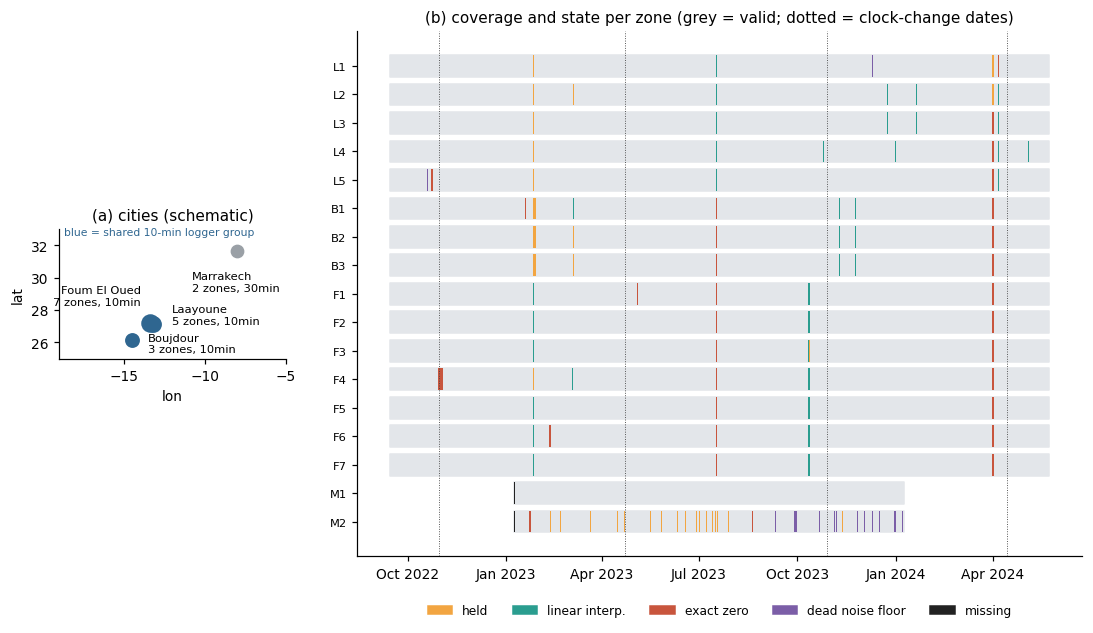

In [6]:
COORDS = {"Laayoune": (-13.20, 27.15), "Foum eloued": (-13.40, 27.19), "Boujdour": (-14.48, 26.13), "Marrakech": (-7.99, 31.63)}

fig = plt.figure(figsize=(12, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 3.2], wspace=.15)
axm = fig.add_subplot(gs[0])
for c, (lon, lat) in COORDS.items():
    col = COL["grid"] if c in SOUTH else COL["normal"]
    axm.scatter(lon, lat, s=40 + 12 * data[c].shape[1], color=col, zorder=3)
    axm.annotate(f"{c.replace('Foum eloued', 'Foum El Oued')}\n{data[c].shape[1]} zones, {R.STEP[c]}",
                 (lon, lat), xytext={"Laayoune": (12, 0), "Foum eloued": (-6, 12), "Boujdour": (10, -8), "Marrakech": (-30, -26)}[c],
                 ha="right" if c == "Foum eloued" else "left", textcoords="offset points", fontsize=7.5)
axm.set_xlim(-19, -5); axm.set_ylim(25, 33); axm.set_aspect("equal")
axm.set_xlabel("lon"); axm.set_ylabel("lat"); axm.set_title("(a) cities (schematic)")
axm.text(-18.7, 32.6, "blue = shared 10-min logger group", fontsize=7, color=COL["grid"])

ax = fig.add_subplot(gs[1])
rows = [(c, z) for c in ["Laayoune", "Boujdour", "Foum eloued", "Marrakech"] for z in data[c].columns]
def spans(mask):
    m = mask.to_numpy(); idx = mask.index
    step = idx[1] - idx[0]
    return [(mdates.date2num(idx[a]), mdates.date2num(idx[b] + step) - mdates.date2num(idx[a])) for a, b in R.runs(pd.Series(m))]
for i, (c, z) in enumerate(rows):
    y = len(rows) - 1 - i
    d = data[c][z]
    ax.broken_barh([(mdates.date2num(d.index[0]), mdates.date2num(d.index[-1]) - mdates.date2num(d.index[0]))], (y - .38, .76), color="#E3E6EA")
    for k, col in [("hold", COL["hold"]), ("interp", COL["interp"]), ("dead_nz", COL["dead"]), ("zero", COL["zero"]), ("missing", COL["missing"])]:
        sp = spans(states[c][k][z])
        if sp: ax.broken_barh(sp, (y - .38, .76), color=col, lw=0)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{CITY_SHORT[c]}{z.replace('zone', '')}" for c, z in rows][::-1], fontsize=7.5)
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for D in ["2022-10-30", "2023-04-23", "2023-10-29", "2024-04-14"]:
    ax.axvline(pd.Timestamp(D), color="#444", lw=.6, ls=":")
ax.set_title("(b) coverage and state per zone (grey = valid; dotted = clock-change dates)")
ax.legend(handles=[Patch(color=COL["hold"], label="held"), Patch(color=COL["interp"], label="linear interp."), Patch(color=COL["zero"], label="exact zero"),
                   Patch(color=COL["dead"], label="dead noise floor"), Patch(color=COL["missing"], label="missing")],
          loc="upper center", bbox_to_anchor=(.5, -.07), ncol=5, fontsize=8)
savefig(fig, "fig1_map_coverage"); plt.show()

## Fig. 3 — 26–29 Jan 2023 (C05 simultaneous hold → C06 zero fill)
Check: L, B and F4 freeze ≈01:20–02:20 on 26 Jan; Boujdour hold ends 28 Jan 21:10 exactly when all 15 zones go to zero (C06, 13.7 h). Boujdour II commissioned 26 Jan 2023.
**New (not in v0):** F1–F3, F5–F7 are *linearly interpolated* 26 Jan 02:20 → 27 Jan 15:40 (constant first difference, teal) — same span as the F4 hold.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\fig3_C05_C06_jan2023.png


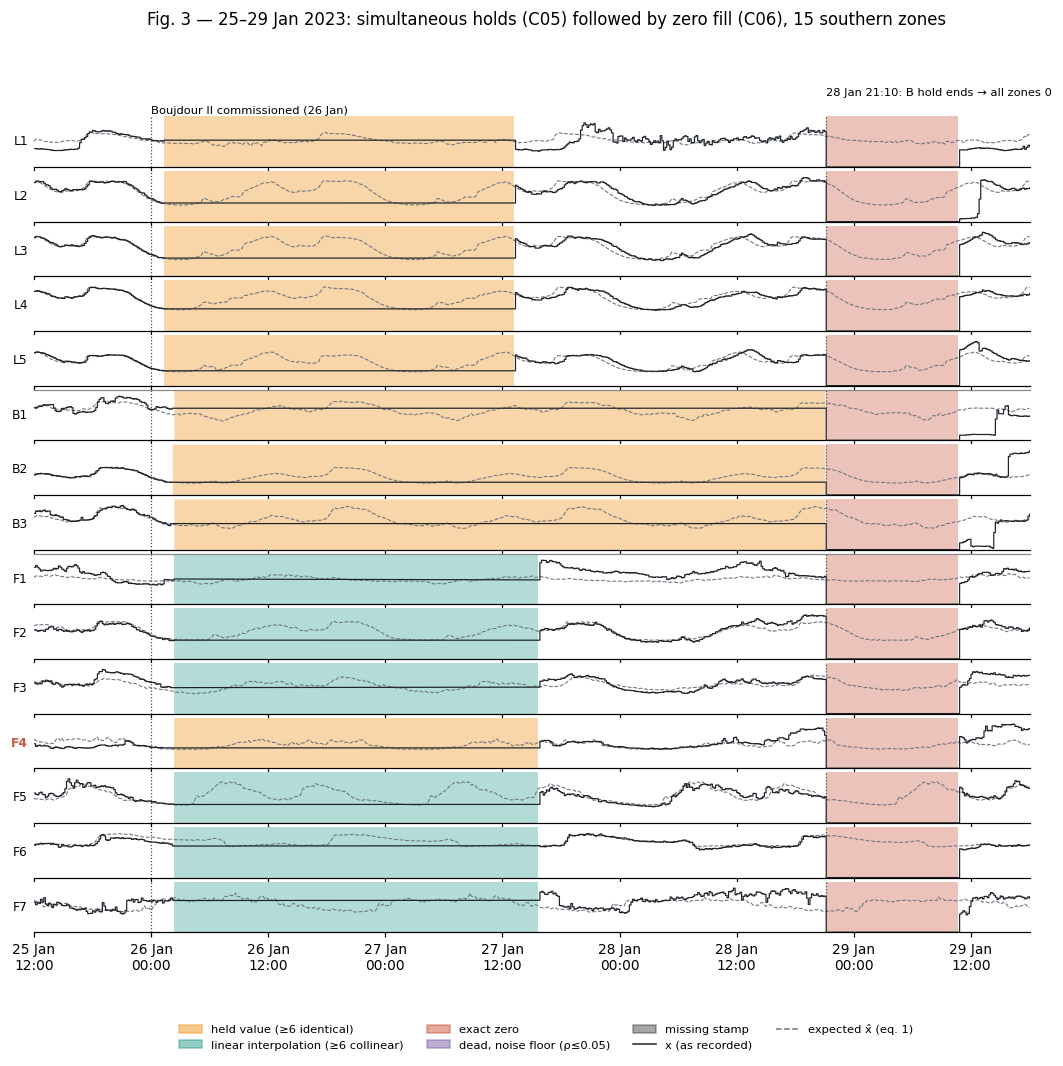

       city  zone               start                 end  points  value
   Boujdour zone1 2023-01-26 02:20:00 2023-01-28 21:10:00     401 77.000
   Boujdour zone2 2023-01-26 02:10:00 2023-01-28 21:10:00     402 12.000
   Boujdour zone3 2023-01-26 02:20:00 2023-01-28 21:10:00     401 31.000
Foum eloued zone4 2023-01-26 02:20:00 2023-01-27 15:50:00     225 18.371
   Laayoune zone1 2023-01-26 01:20:00 2023-01-27 13:20:00     216 57.685
   Laayoune zone2 2023-01-26 01:20:00 2023-01-27 13:20:00     216 74.593
   Laayoune zone3 2023-01-26 01:20:00 2023-01-27 13:20:00     216 92.495
   Laayoune zone4 2023-01-26 01:20:00 2023-01-27 13:20:00     216 74.593
   Laayoune zone5 2023-01-26 01:20:00 2023-01-27 13:20:00     216 78.571
              start                 end  duration_h                        cities  n_zones  exact_zero_share  restore_ratio  peak_ratio  ramp_to_90pct_min  provisional_type
2023-01-28 21:10:00 2023-01-29 10:50:00       13.67 Boujdour+Foum eloued+Laayoune       15       

In [7]:
fig, axes = stack_plot("2023-01-25 12:00", "2023-01-29 18:00",
    title="Fig. 3 — 25–29 Jan 2023: simultaneous holds (C05) followed by zero fill (C06), 15 southern zones",
    marks=[("2023-01-26 00:00", "Boujdour II commissioned (26 Jan)"), ("2023-01-28 21:10", "28 Jan 21:10: B hold ends → all zones 0")],
    highlight=[("Foum eloued", "zone4")])
savefig(fig, "fig3_C05_C06_jan2023"); plt.show()

# numbers behind the figure
print(stuck[(stuck.start >= "2023-01-25") & (stuck.start <= "2023-01-29")].sort_values(["city", "zone"]).to_string(index=False))
print(zero_ev[(zero_ev.start >= "2023-01-28") & (zero_ev.start <= "2023-01-29")][
      ["start", "end", "duration_h", "cities", "n_zones", "exact_zero_share", "restore_ratio", "peak_ratio", "ramp_to_90pct_min", "provisional_type"]].to_string(index=False))

## Fig. 4 — 31 Mar – 2 Apr 2024 (C12: hold → zero, held and zeroed zones side by side)
Check: all B and F zones hold from 09:10; at 11:10 they switch to exact zeros for 43.8 h, while L1 (73.598 A) and L2 (63.652 A) stay frozen.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\fig4_C12_mar2024.png


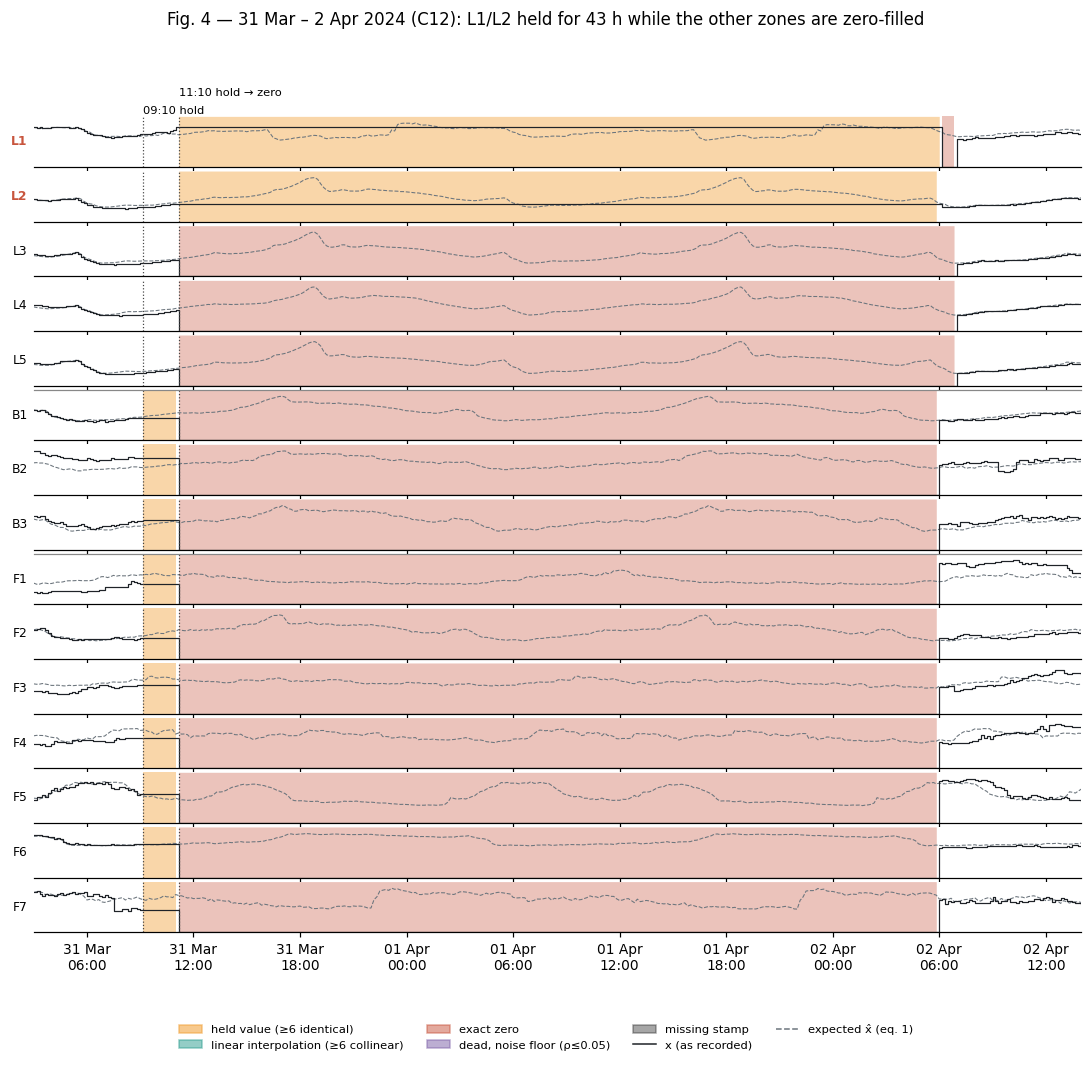

       city  zone               start                 end  points  value
   Boujdour zone1 2024-03-31 09:10:00 2024-03-31 11:10:00      12 38.000
   Boujdour zone2 2024-03-31 09:10:00 2024-03-31 11:10:00      12 51.000
   Boujdour zone3 2024-03-31 09:10:00 2024-03-31 11:10:00      12 41.000
Foum eloued zone1 2024-03-31 09:10:00 2024-03-31 11:10:00      12 31.823
Foum eloued zone2 2024-03-31 09:10:00 2024-03-31 11:10:00      12 36.411
Foum eloued zone3 2024-03-31 09:10:00 2024-03-31 11:10:00      12 66.286
Foum eloued zone4 2024-03-31 09:10:00 2024-03-31 11:10:00      12 23.745
Foum eloued zone5 2024-03-31 09:10:00 2024-03-31 11:10:00      12 15.397
Foum eloued zone6 2024-03-31 09:10:00 2024-03-31 11:10:00      12 21.651
Foum eloued zone7 2024-03-31 09:10:00 2024-03-31 11:10:00      12 39.542
   Laayoune zone1 2024-03-31 11:10:00 2024-04-02 06:10:00     258 73.598
   Laayoune zone2 2024-03-31 11:10:00 2024-04-02 06:00:00     257 63.652


In [8]:
fig, axes = stack_plot("2024-03-31 03:00", "2024-04-02 14:00",
    title="Fig. 4 — 31 Mar – 2 Apr 2024 (C12): L1/L2 held for 43 h while the other zones are zero-filled",
    marks=[("2024-03-31 09:10", "09:10 hold"), ("2024-03-31 11:10", "11:10 hold → zero")],
    highlight=[("Laayoune", "zone1"), ("Laayoune", "zone2")])
savefig(fig, "fig4_C12_mar2024"); plt.show()

print(stuck[(stuck.start >= "2024-03-30") & (stuck.start <= "2024-04-02")].sort_values(["city", "zone"]).to_string(index=False))

## Fig. 5 — Clock evidence (eq. 9)
$\delta^*(D)=\arg\max_{\delta\in[-120,120]}\mathrm{corr}(p_{pre}, \mathrm{shift}_\delta(p_{post}))$, profiles = mean daily shape over 7 days before / after $D$
(per-zone ρ-free normalisation: each zone divided by its own mean, dead/held steps removed, zones averaged).
Sign: **δ > 0 ⇒ after D the same behaviour is stamped δ minutes later.** Unreliable around Ramadan (behaviour changes with the clock).

In [9]:
CLOCK_DATES = {
    "2022-10-30": "Europe fall-back (repeated hour)",
    "2023-03-19": "Morocco → GMT (Ramadan start)",
    "2023-04-23": "Morocco → GMT+1 (missing hour)",
    "2023-10-29": "Europe fall-back (repeated hour)",
    "2024-03-10": "Morocco → GMT (Ramadan start)",
    "2024-04-14": "Morocco → GMT+1 (missing hour)",
}

def city_profile(c, a, b):
    d = data[c][a:b]
    bad = (states[c]["zero"] | states[c]["dead_nz"] | states[c]["hold"])[a:b]
    d = d.where(~bad)
    tod = d.index.hour * 60 + d.index.minute
    p = d.groupby(tod).mean()
    p = p / p.mean()
    return p.mean(axis=1)                       # average normalised zone profile

def clock_offset(c, D, days=7, max_min=120):
    D = pd.Timestamp(D)
    step = int(pd.Timedelta(R.STEP[c]).total_seconds() // 60)
    pre = city_profile(c, D - pd.Timedelta(days=days), D - pd.Timedelta(R.STEP[c]))
    post = city_profile(c, D + pd.Timedelta(days=1), D + pd.Timedelta(days=days + 1) - pd.Timedelta(R.STEP[c]))
    if pre.isna().all() or post.isna().all() or len(pre) != len(post):
        return None
    ks = np.arange(-max_min // step, max_min // step + 1)
    corr = [np.corrcoef(pre.values, np.roll(post.values, -k))[0, 1] for k in ks]
    k_best = ks[int(np.nanargmax(corr))]
    return dict(pre=pre, post=post, shifts=ks * step, corr=np.array(corr), delta=int(k_best * step))

rows = []
for D, lab in CLOCK_DATES.items():
    for c in data:
        d = data[c]
        if not (d.index[0] + pd.Timedelta(days=8) < pd.Timestamp(D) < d.index[-1] - pd.Timedelta(days=8)):
            continue
        r = clock_offset(c, D)
        if r: rows.append(dict(date=D, event=lab, city=c, delta_star_min=r["delta"], corr_at_0=round(r["corr"][len(r["corr"]) // 2], 4), corr_best=round(np.nanmax(r["corr"]), 4)))
clock_tab = pd.DataFrame(rows)
print(clock_tab.to_string(index=False))
clock_tab.to_csv(FIG / "clock_offsets.csv", index=False)

      date                            event        city  delta_star_min  corr_at_0  corr_best
2022-10-30 Europe fall-back (repeated hour)    Laayoune             -60     0.8671     0.9865
2022-10-30 Europe fall-back (repeated hour)    Boujdour             -60     0.8802     0.9781
2022-10-30 Europe fall-back (repeated hour) Foum eloued             -60     0.8585     0.9237
2023-03-19    Morocco → GMT (Ramadan start)    Laayoune              30     0.8385     0.8448
2023-03-19    Morocco → GMT (Ramadan start)    Boujdour               0     0.9025     0.9025
2023-03-19    Morocco → GMT (Ramadan start) Foum eloued              20     0.8805     0.8875
2023-03-19    Morocco → GMT (Ramadan start)   Marrakech              30     0.9444     0.9609
2023-04-23   Morocco → GMT+1 (missing hour)    Laayoune            -120     0.6932     0.7747
2023-04-23   Morocco → GMT+1 (missing hour)    Boujdour              20     0.8416     0.8469
2023-04-23   Morocco → GMT+1 (missing hour) Foum eloued     

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\fig5_clock_2022-10-30.png


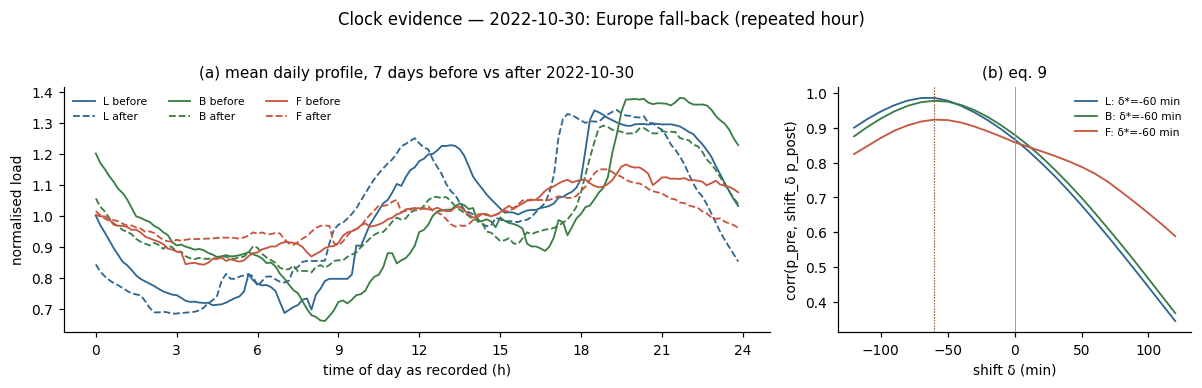

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\figS_clock_2023-04-23.png


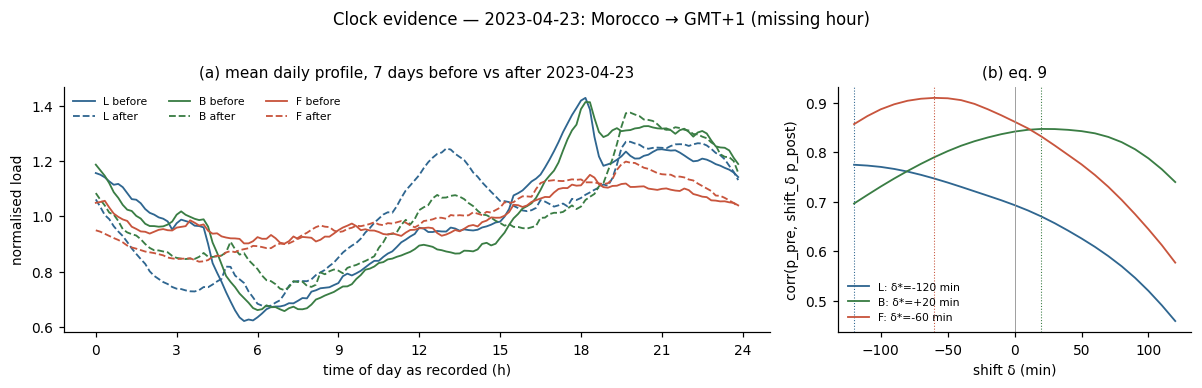

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\figS_clock_2023-10-29.png


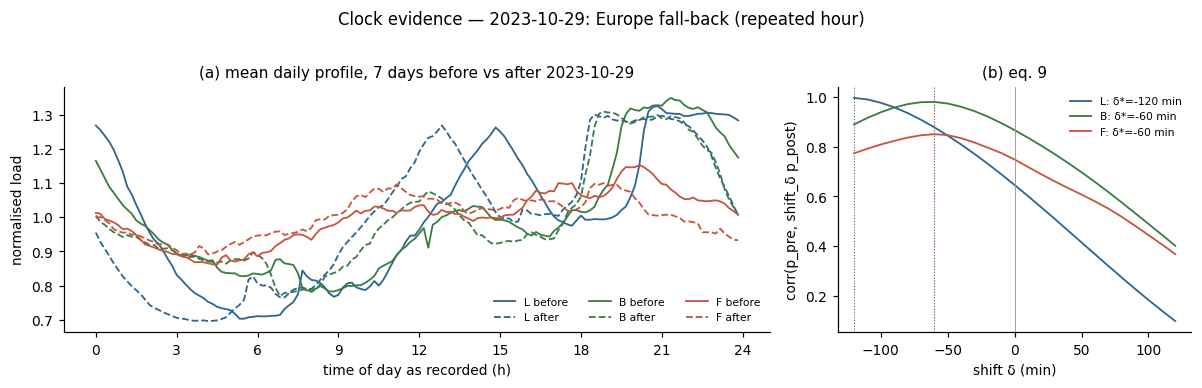

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\figS_clock_2024-04-14.png


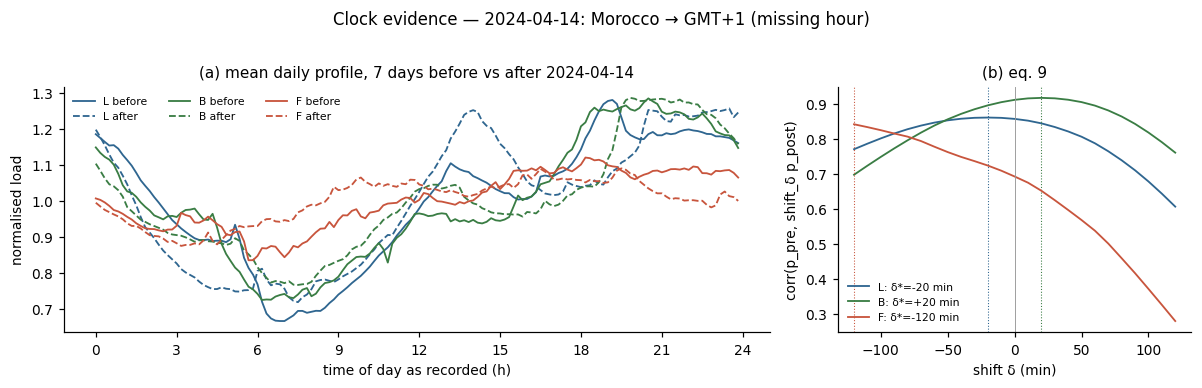

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\figS_clock_2023-03-19.png


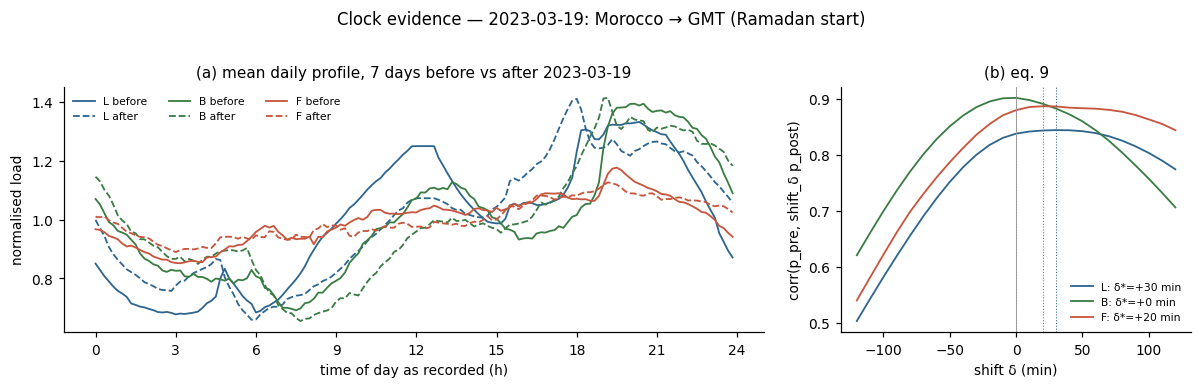

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\figS_clock_2024-03-10.png


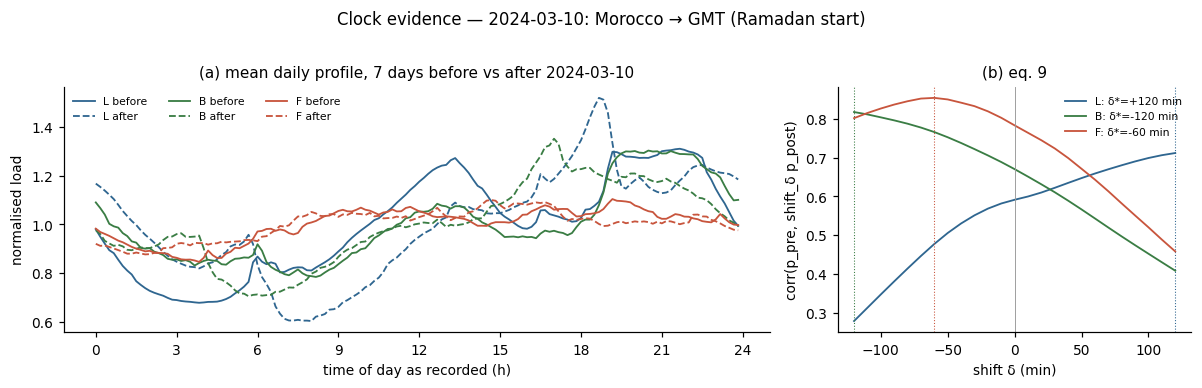

In [10]:
def clock_figure(D):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[2, 1]))
    cols = {"Laayoune": "#2F6690", "Boujdour": "#3A7D44", "Foum eloued": "#C8553D", "Marrakech": "#7B5EA7"}
    for c in SOUTH:
        r = clock_offset(c, D)
        if r is None: continue
        h = r["pre"].index / 60
        axs[0].plot(h, r["pre"].values, color=cols[c], lw=1.2, label=f"{CITY_SHORT[c]} before")
        axs[0].plot(h, r["post"].values, color=cols[c], lw=1.2, ls="--", label=f"{CITY_SHORT[c]} after")
        axs[1].plot(r["shifts"], r["corr"], color=cols[c], lw=1.2, label=f"{CITY_SHORT[c]}: δ*={r['delta']:+d} min")
        axs[1].axvline(r["delta"], color=cols[c], lw=.7, ls=":")
    axs[0].set_xlabel("time of day as recorded (h)"); axs[0].set_ylabel("normalised load"); axs[0].set_xticks(range(0, 25, 3))
    axs[0].set_title(f"(a) mean daily profile, 7 days before vs after {D}")
    axs[0].legend(ncol=3, fontsize=7)
    axs[1].axvline(0, color="#999", lw=.6)
    axs[1].set_xlabel("shift δ (min)"); axs[1].set_ylabel("corr(p_pre, shift_δ p_post)"); axs[1].set_title("(b) eq. 9")
    axs[1].legend(fontsize=7)
    fig.suptitle(f"Clock evidence — {D}: {CLOCK_DATES[D]}", y=1.02)
    fig.tight_layout()
    return fig

fig = clock_figure("2022-10-30"); savefig(fig, "fig5_clock_2022-10-30"); plt.show()
for D in ["2023-04-23", "2023-10-29", "2024-04-14", "2023-03-19", "2024-03-10"]:
    fig = clock_figure(D); savefig(fig, f"figS_clock_{D}"); plt.show()

## E1 — C09, 16 Jul 2023 14:50: candidate regional outage — or artefact?
B and F read exact zeros 14:50 → 07:00; **L is not normal: all 5 L zones are linearly interpolated 15:30 → 06:50** (teal).
Zeros in two cities + straight-line fill in the third = mixed artefact states (R4-type evidence), which argues against G1.
The overshoot π = 1.38 on restoration still needs an explanation.

              start                 end  duration_h               cities                                                                            zones  exact_zero_share  restore_ratio  peak_ratio  ramp_to_90pct_min    provisional_type
2023-07-16 14:50:00 2023-07-17 07:00:00       16.17 Boujdour+Foum eloued Boujdour:zone1,zone2,zone3;Foum eloued:zone1,zone2,zone3,zone4,zone5,zone6,zone7               1.0           1.32        1.38                0.0 G1_regional_outage?


saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E1_C09_jul2023.png


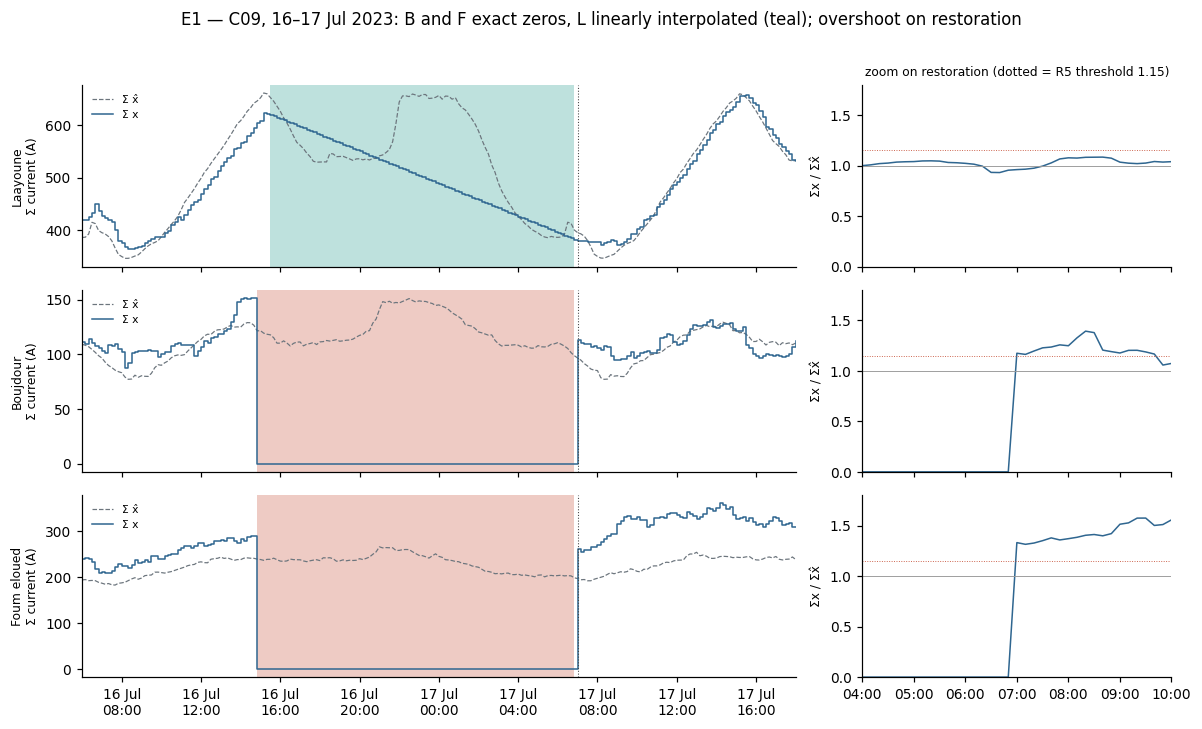

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E1b_C09_stack.png


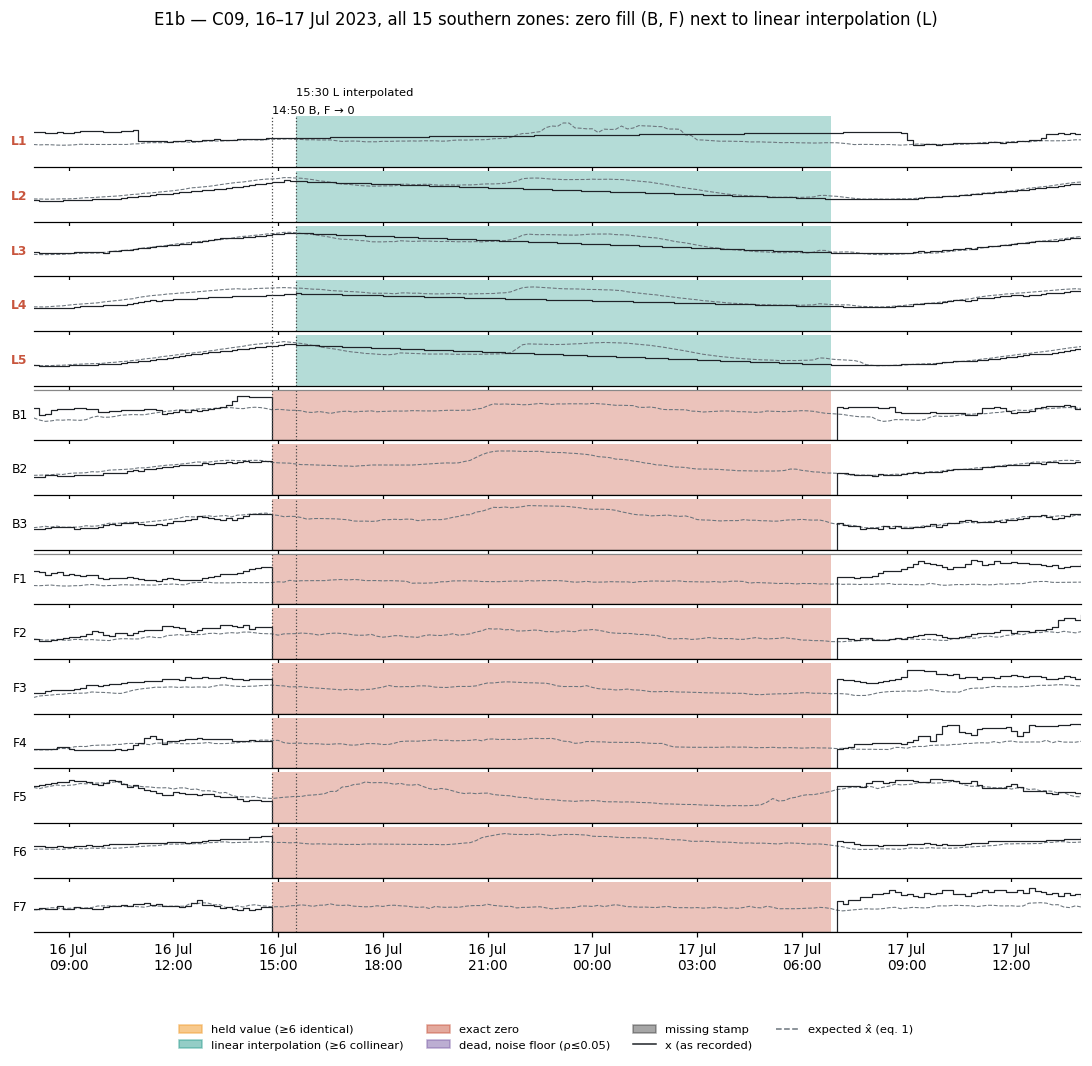

In [11]:
t0, t1 = pd.Timestamp("2023-07-16 06:00"), pd.Timestamp("2023-07-17 18:00")
ev = zero_ev[(zero_ev.start >= "2023-07-16 14:00") & (zero_ev.start <= "2023-07-16 16:00")]
print(ev[["start", "end", "duration_h", "cities", "zones", "exact_zero_share", "restore_ratio", "peak_ratio", "ramp_to_90pct_min", "provisional_type"]].to_string(index=False))
ev_end = ev.end.max() if len(ev) else None

fig, axs = plt.subplots(3, 2, figsize=(11, 6.5), sharex="col", gridspec_kw=dict(width_ratios=[3, 1.3]))
for i, c in enumerate(SOUTH):
    tot = data[c].sum(axis=1, min_count=1)[t0:t1]; etot = exp[c].sum(axis=1, min_count=1)[t0:t1]
    ax = axs[i, 0]
    ax.plot(etot.index, etot.values, color=COL["expected"], ls="--", lw=.8, label="Σ x̂")
    ax.plot(tot.index, tot.values, color=COL["grid"], lw=1, drawstyle="steps-post", label="Σ x")
    for k in ("zero", "interp", "hold"):
        allz = states[c][k][t0:t1].all(axis=1)
        ax.fill_between(tot.index, 0, 1, where=allz.to_numpy(), step="post", color=COL[k], alpha=.3, transform=ax.get_xaxis_transform(), lw=0)
    ax.set_ylabel(f"{c}\nΣ current (A)", fontsize=8); ax.legend(fontsize=7, loc="upper left")
    ax2 = axs[i, 1]
    ratio = (tot / etot)
    ax2.plot(ratio.index, ratio.values, color=COL["grid"], lw=1)
    ax2.axhline(1, color="#999", lw=.6); ax2.axhline(1.15, color=COL["artefact"], lw=.6, ls=":")
    ax2.set_ylim(0, 1.8); ax2.set_ylabel("Σx / Σx̂", fontsize=8)
    if ev_end is not None:
        ax2.set_xlim(ev_end - pd.Timedelta("3h"), ev_end + pd.Timedelta("3h"))
        ax.axvline(ev_end, color="#444", lw=.7, ls=":")
fmt_time(axs[-1, 0]); fmt_time(axs[-1, 1], "%H:%M")
axs[0, 1].set_title("zoom on restoration (dotted = R5 threshold 1.15)", fontsize=8)
axs[0, 0].set_xlim(t0, t1)
fig.suptitle("E1 — C09, 16–17 Jul 2023: B and F exact zeros, L linearly interpolated (teal); overshoot on restoration", y=1.01)
fig.tight_layout(); savefig(fig, "E1_C09_jul2023"); plt.show()

fig, axes = stack_plot("2023-07-16 08:00", "2023-07-17 14:00",
    title="E1b — C09, 16–17 Jul 2023, all 15 southern zones: zero fill (B, F) next to linear interpolation (L)",
    marks=[("2023-07-16 14:50", "14:50 B, F → 0"), ("2023-07-16 15:30", "15:30 L interpolated")],
    highlight=[("Laayoune", z) for z in data["Laayoune"].columns])
savefig(fig, "E1b_C09_stack"); plt.show()

## E2 — C11, Boujdour load transfer on 16 Dec 2023 (eq. 8, κ = |ΣΔ| / max|Δ|)

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E2_C11_transfer.png


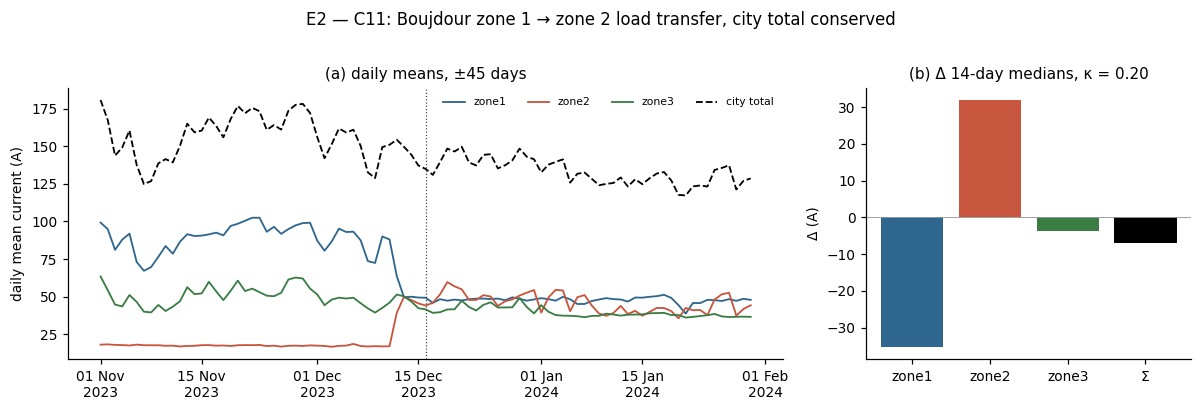

       city        day zone_up  delta_up zone_down  delta_down  conservation_index     score
   Boujdour 2023-12-16   zone2      33.0     zone1       -31.9                0.07 60.654206
Foum eloued 2022-10-07   zone4      15.6     zone2       -35.2                0.97 25.786802
Foum eloued 2023-05-03   zone6       9.9     zone2       -50.4                2.99 15.112782
Foum eloued 2023-02-21   zone3      34.3     zone6        -7.6                1.85 14.701754
Foum eloued 2023-04-19   zone2      58.2     zone6        -6.6                3.61 14.056399
Foum eloued 2023-03-15   zone6       6.5     zone7       -42.4                2.94 12.411168
Foum eloued 2023-04-16   zone4      12.4     zone6        -8.5                0.72 12.151163
Foum eloued 2023-03-24   zone6      10.3     zone1       -17.7                1.45 11.428571
Foum eloued 2023-02-27   zone7      25.5     zone6        -6.6                1.85 11.263158
Foum eloued 2022-12-19   zone6       8.3     zone3       -44.7        

In [12]:
c = "Boujdour"; D = pd.Timestamp("2023-12-16")
daily = data[c].where(data[c] > 0).resample("1D").mean()
win = daily[D - pd.Timedelta(days=45): D + pd.Timedelta(days=45)]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
for z, col in zip(win.columns, ["#2F6690", "#C8553D", "#3A7D44"]):
    axs[0].plot(win.index, win[z], color=col, lw=1.2, label=z)
axs[0].plot(win.index, win.sum(axis=1), color="black", lw=1.2, ls="--", label="city total")
axs[0].axvline(D, color="#444", lw=.8, ls=":")
axs[0].set_ylabel("daily mean current (A)"); axs[0].legend(fontsize=7, ncol=4)
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
axs[0].set_title("(a) daily means, ±45 days")
t = transf[transf.city == c].copy()
row = t[t.day == D]
pre = daily[D - pd.Timedelta(days=14): D - pd.Timedelta(days=1)].median()
post = daily[D: D + pd.Timedelta(days=13)].median()
delta = post - pre
axs[1].bar(delta.index, delta.values, color=["#2F6690", "#C8553D", "#3A7D44"])
axs[1].bar(["Σ"], [delta.sum()], color="black")
kappa = abs(delta.sum()) / delta.abs().max()
axs[1].axhline(0, color="#999", lw=.6)
axs[1].set_title(f"(b) Δ 14-day medians, κ = {kappa:.2f}"); axs[1].set_ylabel("Δ (A)")
fig.suptitle("E2 — C11: Boujdour zone 1 → zone 2 load transfer, city total conserved", y=1.02)
fig.tight_layout(); savefig(fig, "E2_C11_transfer"); plt.show()
print(transf.to_string(index=False))

## E3 — Single-zone dead events: maintenance window (R10 / G4) vs unplanned (G3)

68 single-zone events; start 06-11h: 57; weekend: 33


saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E3_single_zone_timing.png


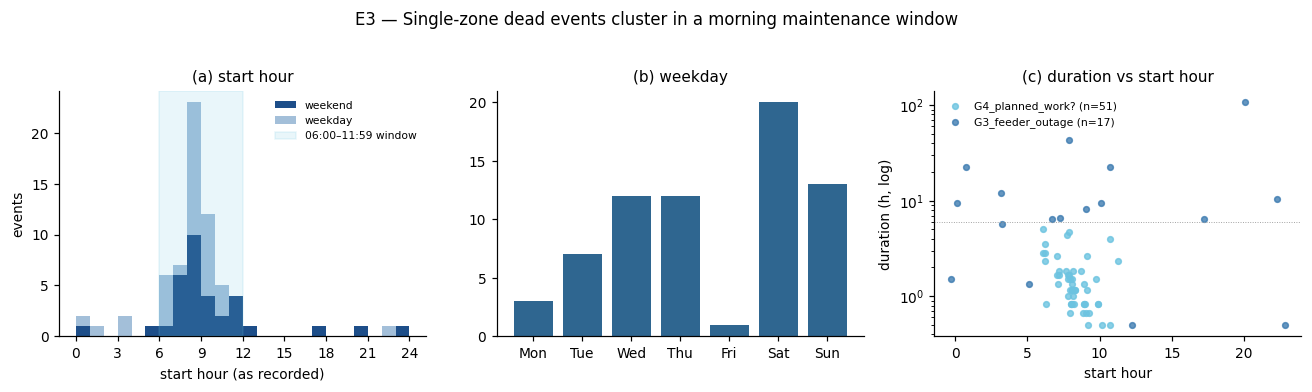

In [13]:
sz = zero_ev[zero_ev.n_zones == 1].copy()
sz["weekend"] = sz.weekday.isin(["Sat", "Sun"])
print(f"{len(sz)} single-zone events; start 06-11h: {sz.start_hour.between(6, 11).sum()}; weekend: {sz.weekend.sum()}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
hrs = np.arange(25)
axs[0].hist([sz[sz.weekend].start_hour, sz[~sz.weekend].start_hour], bins=hrs, stacked=True,
            color=["#1D4E89", "#A3BFD9"], label=["weekend", "weekday"])
axs[0].axvspan(6, 12, color="#6CC3E0", alpha=.15, label="06:00–11:59 window")
axs[0].set_xlabel("start hour (as recorded)"); axs[0].set_ylabel("events"); axs[0].legend(fontsize=7); axs[0].set_xticks(range(0, 25, 3))
axs[0].set_title("(a) start hour")
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axs[1].bar(order, sz.weekday.value_counts().reindex(order, fill_value=0), color=COL["grid"])
axs[1].set_title("(b) weekday")
for typ, col in [("G4_planned_work?", TYPE_COL["G4_planned_work?"]), ("G3_feeder_outage", TYPE_COL["G3_feeder_outage"])]:
    s = sz[sz.provisional_type == typ]
    axs[2].scatter(s.start_hour + np.random.default_rng(0).uniform(-.3, .3, len(s)), s.duration_h, s=14, color=col, label=f"{typ} (n={len(s)})", alpha=.8)
axs[2].set_yscale("log"); axs[2].set_xlabel("start hour"); axs[2].set_ylabel("duration (h, log)"); axs[2].legend(fontsize=7)
axs[2].axhline(6, color="#999", lw=.6, ls=":"); axs[2].set_title("(c) duration vs start hour")
fig.suptitle("E3 — Single-zone dead events cluster in a morning maintenance window", y=1.03)
fig.tight_layout(); savefig(fig, "E3_single_zone_timing"); plt.show()

## E4 — Signatures: exact-zero share η (H1) and restoration (H2) by provisional type

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E4_signatures.png


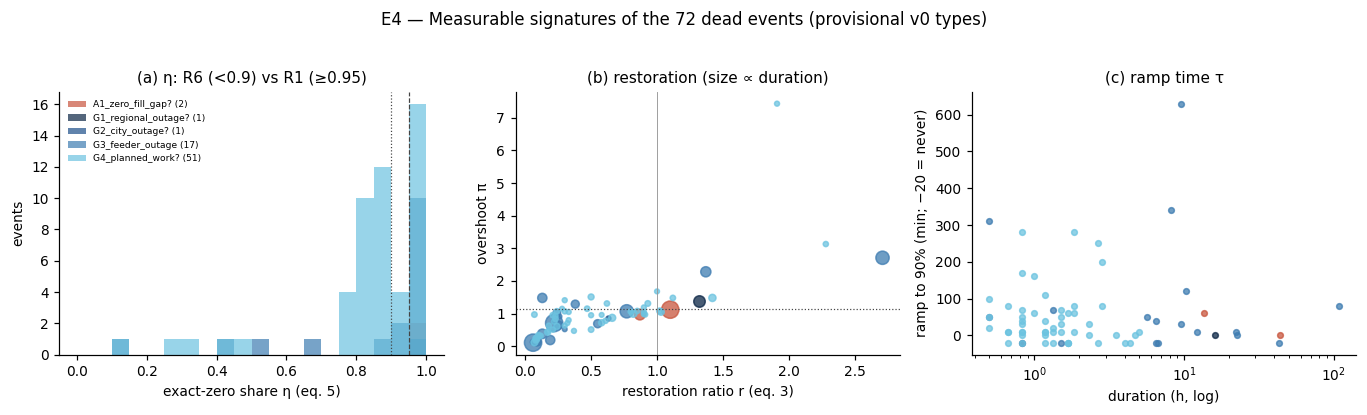

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6))
bins = np.linspace(0, 1, 21)
for t, g in zero_ev.groupby("provisional_type"):
    axs[0].hist(g.exact_zero_share, bins=bins, alpha=.7, color=TYPE_COL.get(t, "#999"), label=f"{t} ({len(g)})")
axs[0].axvline(.9, color="#444", ls=":", lw=.8); axs[0].axvline(.95, color="#444", ls="--", lw=.8)
axs[0].set_xlabel("exact-zero share η (eq. 5)"); axs[0].set_ylabel("events"); axs[0].legend(fontsize=6)
axs[0].set_title("(a) η: R6 (<0.9) vs R1 (≥0.95)")
for t, g in zero_ev.groupby("provisional_type"):
    axs[1].scatter(g.restore_ratio, g.peak_ratio, s=8 + 3 * g.duration_h.clip(upper=40), color=TYPE_COL.get(t, "#999"), alpha=.75, label=t)
axs[1].axhline(1.15, color="#444", ls=":", lw=.8); axs[1].axvline(1, color="#999", lw=.6)
axs[1].set_xlabel("restoration ratio r (eq. 3)"); axs[1].set_ylabel("overshoot π"); axs[1].set_title("(b) restoration (size ∝ duration)")
for t, g in zero_ev.groupby("provisional_type"):
    axs[2].scatter(g.duration_h, g.ramp_to_90pct_min.fillna(-20), s=14, color=TYPE_COL.get(t, "#999"), alpha=.75)
axs[2].set_xscale("log"); axs[2].set_xlabel("duration (h, log)"); axs[2].set_ylabel("ramp to 90% (min; −20 = never)")
axs[2].set_title("(c) ramp time τ")
fig.suptitle("E4 — Measurable signatures of the 72 dead events (provisional v0 types)", y=1.03)
fig.tight_layout(); savefig(fig, "E4_signatures"); plt.show()

## E5 — Single-zone outage gallery (C01, C02, C04, C07)
Dead zone (bold) vs its expected value; neighbours of the same city in light grey (normalised by their own expected value → ρ).

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E5_single_zone_gallery.png


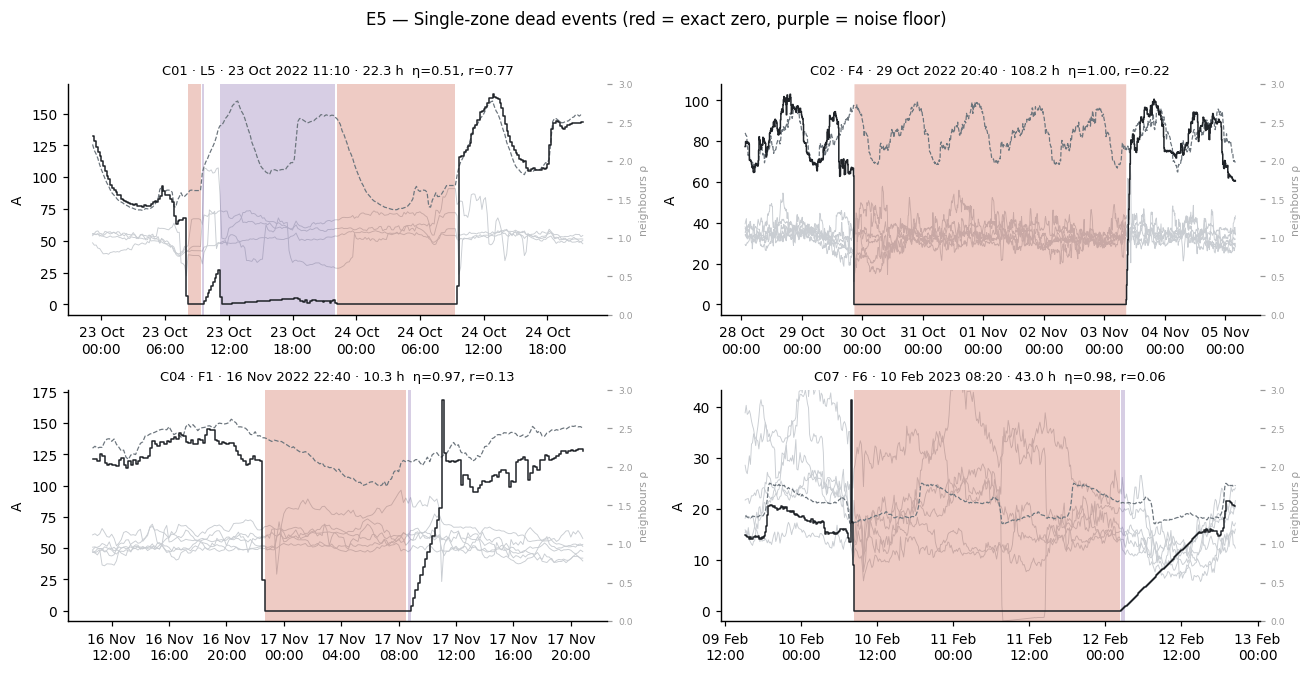

In [15]:
GALLERY = [("C01", "Laayoune", "zone5", "2022-10-23 11:10", 22.3),
           ("C02", "Foum eloued", "zone4", "2022-10-29 20:40", 108.2),
           ("C04", "Foum eloued", "zone1", "2022-11-16 22:40", 10.3),
           ("C07", "Foum eloued", "zone6", "2023-02-10 08:20", 43.0)]
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
for ax, (cid, c, z, s, dur) in zip(axs.flat, GALLERY):
    s = pd.Timestamp(s); e = s + pd.Timedelta(hours=dur)
    pad = pd.Timedelta(hours=max(12, dur * .4))
    t0, t1 = s - pad, e + pad
    x = data[c][z][t0:t1]; xh = exp[c][z][t0:t1]
    ax2 = ax.twinx()
    for zz in data[c].columns:
        if zz == z: continue
        rho = (data[c][zz] / exp[c][zz])[t0:t1]
        ax2.plot(rho.index, rho.values, color="#C9CDD2", lw=.6)
    ax2.set_ylim(0, 3); ax2.set_ylabel("neighbours ρ", color="#999", fontsize=7); ax2.tick_params(labelsize=6, colors="#999")
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    tr = ax.get_xaxis_transform()
    ax.fill_between(x.index, 0, 1, where=states[c]["zero"][z][t0:t1].to_numpy(), step="post", color=COL["zero"], alpha=.3, transform=tr, lw=0)
    ax.fill_between(x.index, 0, 1, where=states[c]["dead_nz"][z][t0:t1].to_numpy(), step="post", color=COL["dead"], alpha=.3, transform=tr, lw=0)
    ax.plot(xh.index, xh.values, color=COL["expected"], ls="--", lw=.8)
    ax.plot(x.index, x.values, color=COL["trace"], lw=1, drawstyle="steps-post")
    r = zero_ev[(zero_ev.start == s)]
    info = f"η={r.exact_zero_share.iloc[0]:.2f}, r={r.restore_ratio.iloc[0]}" if len(r) else ""
    ax.set_title(f"{cid} · {CITY_SHORT[c]}{z[-1]} · {s:%d %b %Y %H:%M} · {dur} h  {info}", fontsize=8.5)
    ax.set_ylabel("A"); fmt_time(ax)
fig.suptitle("E5 — Single-zone dead events (red = exact zero, purple = noise floor)", y=1.01)
fig.tight_layout(); savefig(fig, "E5_single_zone_gallery"); plt.show()

## E6 — Catalogue overview: every v0 event on one timeline

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E6_catalogue_timeline.png


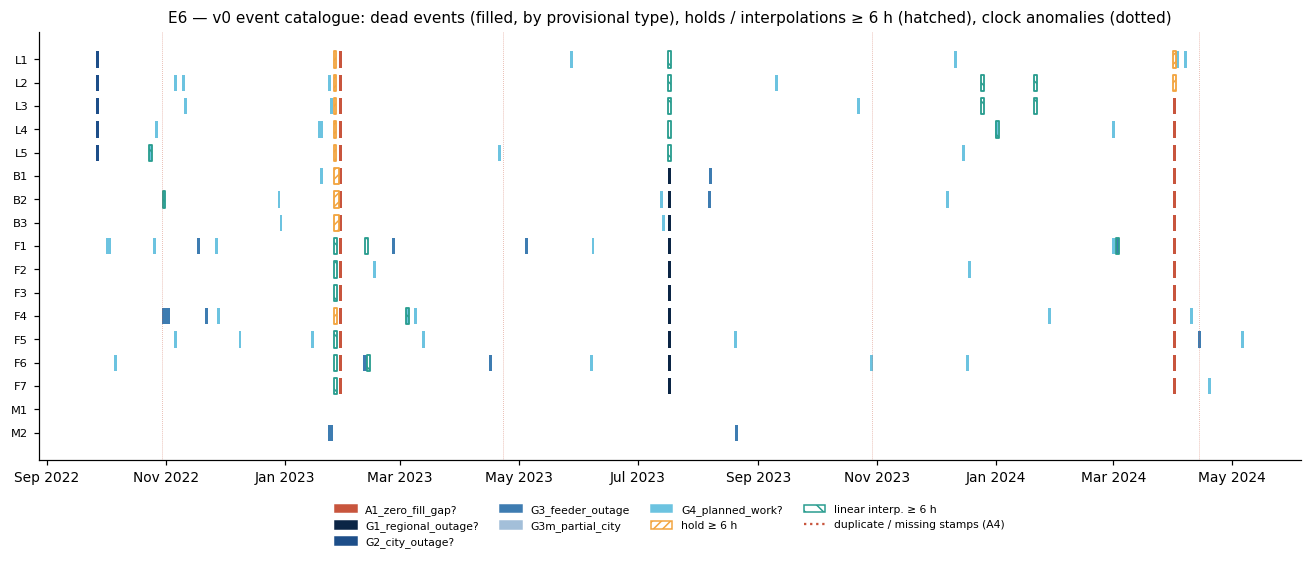

In [16]:
rows = [(c, z) for c in ["Laayoune", "Boujdour", "Foum eloued", "Marrakech"] for z in data[c].columns]
ypos = {r: len(rows) - 1 - i for i, r in enumerate(rows)}
inv = {v: k for k, v in CITY_SHORT.items()}
fig, ax = plt.subplots(figsize=(12, 5.2))
for _, e in zero_ev.iterrows():
    col = TYPE_COL.get(e.provisional_type, "#999")
    for part in e.zones.split(";"):
        c, zs = part.split(":")
        for z in zs.split(","):
            w = max(mdates.date2num(e.end) - mdates.date2num(e.start), 1.5)   # widen to >= 1.5 days for visibility
            ax.broken_barh([(mdates.date2num(e.start), w)], (ypos[(c, z)] - .35, .7), color=col, lw=0)
for _, s in stuck[stuck.points >= 36].iterrows():   # holds >= 6 h (10-min data)
    ax.broken_barh([(mdates.date2num(s.start), max(mdates.date2num(s.end) - mdates.date2num(s.start), 1.5))],
                   (ypos[(s.city, s.zone)] - .35, .7), facecolor="none", edgecolor=COL["hold"], lw=1.2, hatch="////")
for c in SOUTH:
    for z in data[c].columns:
        m = states[c]["interp"][z]
        for a, b in R.runs(m):
            if b - a + 1 >= 36:
                ax.broken_barh([(mdates.date2num(m.index[a]), max(mdates.date2num(m.index[b]) - mdates.date2num(m.index[a]), 1.5))],
                               (ypos[(c, z)] - .35, .7), facecolor="none", edgecolor=COL["interp"], lw=1.2, hatch="\\\\")
for D in audit[audit.kind.isin(["duplicate", "missing_run"]) & audit.city.isin(SOUTH)].timestamp.dt.normalize().unique():
    ax.axvline(D, color=COL["artefact"], lw=.5, ls=":", alpha=.6)
ax.set_yticks(list(ypos.values())); ax.set_yticklabels([f"{CITY_SHORT[c]}{z[-1]}" for c, z in ypos.keys()], fontsize=7.5)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
handles = [Patch(color=v, label=k) for k, v in TYPE_COL.items()] + \
          [Patch(facecolor="none", edgecolor=COL["hold"], hatch="////", label="hold ≥ 6 h"),
           Patch(facecolor="none", edgecolor=COL["interp"], hatch="\\\\", label="linear interp. ≥ 6 h"),
           Line2D([], [], color=COL["artefact"], ls=":", label="duplicate / missing stamps (A4)")]
ax.legend(handles=handles, fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.08))
ax.set_title("E6 — v0 event catalogue: dead events (filled, by provisional type), holds / interpolations ≥ 6 h (hatched), clock anomalies (dotted)")
fig.tight_layout(); savefig(fig, "E6_catalogue_timeline"); plt.show()

## E7 — Foum El Oued structural decline (flag S) and midday/evening ratio
Midday = 11:00–14:59, evening = 18:00–21:59 (as recorded). Dead and held steps removed.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E7_FoumElOued_structural.png


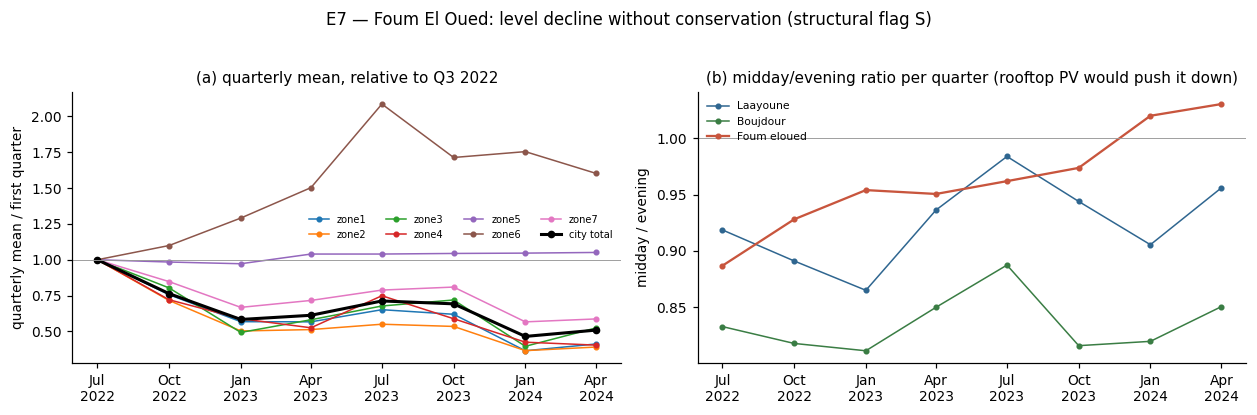

            F_total_rel  F_mid/eve
2022-07-01         1.00       0.89
2022-10-01         0.76       0.93
2023-01-01         0.58       0.95
2023-04-01         0.61       0.95
2023-07-01         0.71       0.96
2023-10-01         0.69       0.97
2024-01-01         0.47       1.02
2024-04-01         0.51       1.03


In [17]:
c = "Foum eloued"
bad = states[c]["zero"] | states[c]["dead_nz"] | states[c]["hold"]
clean = data[c].where(~bad)
q = clean.resample("QS").mean()
q_tot = clean.sum(axis=1, min_count=data[c].shape[1]).resample("QS").mean()
hr = clean.index.hour
mid = clean[(hr >= 11) & (hr < 15)].sum(axis=1, min_count=data[c].shape[1]).resample("QS").mean()
eve = clean[(hr >= 18) & (hr < 22)].sum(axis=1, min_count=data[c].shape[1]).resample("QS").mean()
ratio = mid / eve

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
for z in q.columns:
    axs[0].plot(q.index, q[z] / q[z].iloc[0], marker="o", ms=3, lw=1, label=z)
axs[0].plot(q_tot.index, q_tot / q_tot.iloc[0], color="black", lw=2, marker="o", ms=4, label="city total")
axs[0].axhline(1, color="#999", lw=.6); axs[0].set_ylabel("quarterly mean / first quarter")
axs[0].legend(fontsize=6.5, ncol=4); axs[0].set_title("(a) quarterly mean, relative to Q3 2022")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
for city, col in zip(SOUTH, ["#2F6690", "#3A7D44", "#C8553D"]):
    b = states[city]["zero"] | states[city]["dead_nz"] | states[city]["hold"]
    cl = data[city].where(~b); h = cl.index.hour; n = data[city].shape[1]
    r_ = cl[(h >= 11) & (h < 15)].sum(axis=1, min_count=n).resample("QS").mean() / cl[(h >= 18) & (h < 22)].sum(axis=1, min_count=n).resample("QS").mean()
    axs[1].plot(r_.index, r_.values, marker="o", ms=3, color=col, lw=1.5 if city == c else 1, label=city)
axs[1].axhline(1, color="#999", lw=.6); axs[1].set_ylabel("midday / evening"); axs[1].legend(fontsize=7)
axs[1].set_title("(b) midday/evening ratio per quarter (rooftop PV would push it down)")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("E7 — Foum El Oued: level decline without conservation (structural flag S)", y=1.03)
fig.tight_layout(); savefig(fig, "E7_FoumElOued_structural"); plt.show()
print(pd.DataFrame({"F_total_rel": (q_tot / q_tot.iloc[0]).round(2), "F_mid/eve": ratio.round(2)}).to_string())

## E8 — Marrakech timestamp audit (A4 in a 30-min system)

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures\E8_Marrakech_timestamps.png


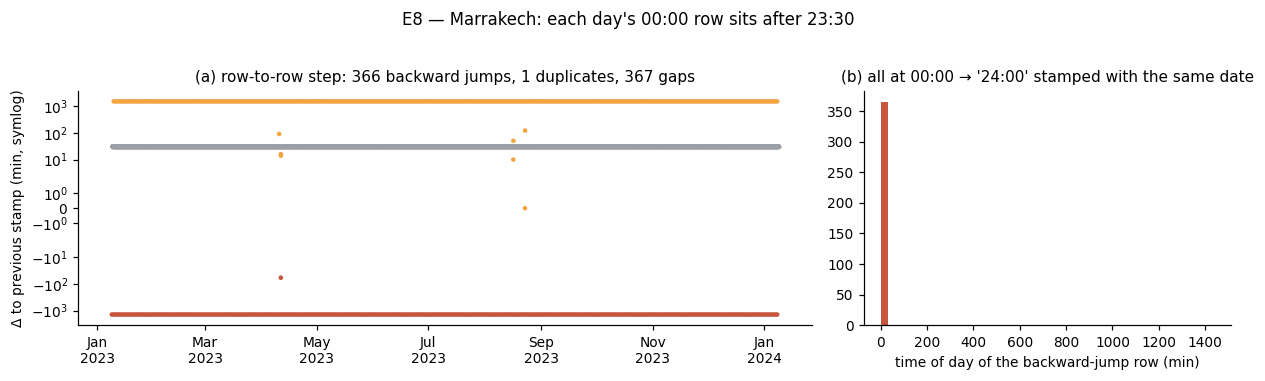

              DateTime  zone1  zone2
73 2023-01-10 22:30:00    996     19
74 2023-01-10 23:00:00    931     20
75 2023-01-10 23:30:00    933     19
76 2023-01-10 00:00:00    825     20
77 2023-01-11 00:30:00    775     21


In [18]:
t = raw["Marrakech"]["DateTime"]
dt_min = t.diff().dt.total_seconds() / 60
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.3), gridspec_kw=dict(width_ratios=[2, 1]))
axs[0].scatter(t, dt_min, s=4, c=np.where(dt_min < 0, COL["artefact"], np.where(dt_min == 30, COL["normal"], COL["hold"])))
axs[0].set_yscale("symlog"); axs[0].set_ylabel("Δ to previous stamp (min, symlog)")
axs[0].set_title(f"(a) row-to-row step: {int((dt_min < 0).sum())} backward jumps, {int((dt_min == 0).sum())} duplicates, {int((dt_min > 30).sum())} gaps")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
back = t[dt_min < 0]
axs[1].hist(back.dt.hour * 60 + back.dt.minute, bins=np.arange(0, 1441, 30), color=COL["artefact"])
axs[1].set_xlabel("time of day of the backward-jump row (min)"); axs[1].set_title("(b) all at 00:00 → '24:00' stamped with the same date")
fig.suptitle("E8 — Marrakech: each day's 00:00 row sits after 23:30", y=1.03)
fig.tight_layout(); savefig(fig, "E8_Marrakech_timestamps"); plt.show()
i = int(np.where(dt_min < 0)[0][1]); print(raw["Marrakech"].iloc[i - 3:i + 2].to_string())

## New artefact signature — linear-interpolation runs (not detected by v0)
Runs of ≥ 6 collinear non-zero points with non-zero slope, grouped across zones by start time (±10 min) like v0 events.

In [19]:
recs = []
for c, d in data.items():
    step = pd.Timedelta(R.STEP[c])
    for z in d.columns:
        m = states[c]["interp"][z]
        for a, b in R.runs(m):
            recs.append(dict(city=c, zone=z, start=m.index[a], end=m.index[b] + step, points=b - a + 1,
                             slope_per_step=round(float(d[z].diff().iloc[b]), 5)))
interp_runs = pd.DataFrame(recs).sort_values("start").reset_index(drop=True)
g, first = [], None
for s in interp_runs.start:
    if first is None or s - first > pd.Timedelta("10min"):
        first = s; g.append(1)
    else:
        g.append(0)
interp_runs["group"] = np.cumsum(g)
grp = (interp_runs.groupby("group")
       .agg(start=("start", "min"), end=("end", "max"), n_zones=("zone", "size"),
            cities=("city", lambda x: "+".join(sorted(set(x)))), max_points=("points", "max"))
       .assign(duration_h=lambda t: ((t.end - t.start).dt.total_seconds() / 3600).round(2))
       .sort_values(["n_zones", "duration_h"], ascending=False))
interp_runs.to_csv(FIG / "interp_runs.csv", index=False)
print(len(interp_runs), "interpolation runs in", len(grp), "groups;", int((grp.n_zones >= 2).sum()), "groups touch >= 2 zones at once")
print(grp.head(15).to_string(index=False))

275 interpolation runs in 102 groups; 48 groups touch >= 2 zones at once
              start                 end  n_zones               cities  max_points  duration_h
2023-03-30 12:30:00 2023-03-30 14:00:00        9 Boujdour+Foum eloued           9        1.50
2023-09-08 03:10:00 2023-09-08 04:30:00        9 Boujdour+Foum eloued           8        1.33
2023-10-11 09:20:00 2023-10-11 11:30:00        7          Foum eloued          13        2.17
2024-03-14 09:40:00 2024-03-14 11:00:00        7          Foum eloued           8        1.33
2023-07-18 09:40:00 2023-07-18 10:50:00        7          Foum eloued           7        1.17
2023-10-10 09:40:00 2023-10-10 10:50:00        7          Foum eloued           7        1.17
2024-02-13 09:20:00 2024-02-13 10:30:00        7          Foum eloued           7        1.17
2023-10-14 10:20:00 2023-10-14 11:20:00        7          Foum eloued           6        1.00
2024-02-15 08:50:00 2024-02-15 09:50:00        7          Foum eloued           6

In [20]:
print("Figures written to", FIG)
for p in sorted(FIG.glob("*.png")): print(" ", p.name)

Figures written to C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures
  E1_C09_jul2023.png
  E1b_C09_stack.png
  E2_C11_transfer.png
  E3_single_zone_timing.png
  E4_signatures.png
  E5_single_zone_gallery.png
  E6_catalogue_timeline.png
  E7_FoumElOued_structural.png
  E8_Marrakech_timestamps.png
  fig1_map_coverage.png
  fig3_C05_C06_jan2023.png
  fig4_C12_mar2024.png
  fig5_clock_2022-10-30.png
  figS_clock_2023-03-19.png
  figS_clock_2023-04-23.png
  figS_clock_2023-10-29.png
  figS_clock_2024-03-10.png
  figS_clock_2024-04-14.png
